### Spam Mail Detection

- dataset link: https://www.kaggle.com/datasets/venky73/spam-mails-dataset

In [22]:
# Import the required libraries
import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [23]:
# Load the dataset
df = pd.read_csv('./datasets/assignment-03.csv')

print(df.head())

   Unnamed: 0  ... label_num
0         605  ...         0
1        2349  ...         0
2        3624  ...         0
3        4685  ...         1
4        2030  ...         0

[5 rows x 4 columns]


In [24]:
# Explore the dataset

print("\nDataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("Class Distribution:\n", df['label'].value_counts())


Dataset Shape: (5171, 4)

Columns: ['Unnamed: 0', 'label', 'text', 'label_num']
Class Distribution:
 label
ham     3672
spam    1499
Name: count, dtype: int64


In [25]:
# Prepare the email texts and labels
df = df[["text", "label"]].dropna()

df["text"]=df["text"].astype(str)
df["label"]=df["label"].astype(str).str.lower().str.strip()

df = df[df["label"].isin(["spam", "ham"])]
df["label"] = df["label"].map({"ham": 0, "spam": 1})


print(df.head())
print("\nClass Distribution:")
print(df['label'].value_counts())

                                                text  label
0  Subject: enron methanol ; meter # : 988291\r\n...      0
1  Subject: hpl nom for january 9 , 2001\r\n( see...      0
2  Subject: neon retreat\r\nho ho ho , we ' re ar...      0
3  Subject: photoshop , windows , office . cheap ...      1
4  Subject: re : indian springs\r\nthis deal is t...      0

Class Distribution:
label
0    3672
1    1499
Name: count, dtype: int64


In [26]:
# Preproces the email text
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+"," ", text) # Remove weblinks from the text
    text = re.sub(r"[^a-z\s]", " ", text) # Remove special characters and numbers
    text = re.sub(r"\s+", " ", text).strip() #Clean up extra spaces
    return text

df["text"] = df["text"].apply(preprocess_text)

print(df[["text", "label"]].head())

                                                text  label
0  subject enron methanol meter this is a follow ...      0
1  subject hpl nom for january see attached file ...      0
2  subject neon retreat ho ho ho we re around to ...      0
3  subject photoshop windows office cheap main tr...      1
4  subject re indian springs this deal is to book...      0


In [27]:
# Split the dataset
X=df["text"]
y=df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

Training emails: 4136
Testing emails: 1035


In [28]:
# Convert email text to numerical features using TF-IDF
vectorizer = TfidfVectorizer(stop_words="english",max_features=5000)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


print("Training features shape:", X_train_tfidf.shape)
print("Testing features shape:", X_test_tfidf.shape)

Training features shape: (4136, 5000)
Testing features shape: (1035, 5000)


In [29]:
# Train the spam classifier
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("Email spam classifier trained successfully.")

Email spam classifier trained successfully.


Accuracy: 95.07 %
Classification Report:

              precision    recall  f1-score   support

         Ham       0.97      0.96      0.97       742
        Spam       0.90      0.93      0.91       293

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035

Confusion Matrix:
 [[712  30]
 [ 21 272]]


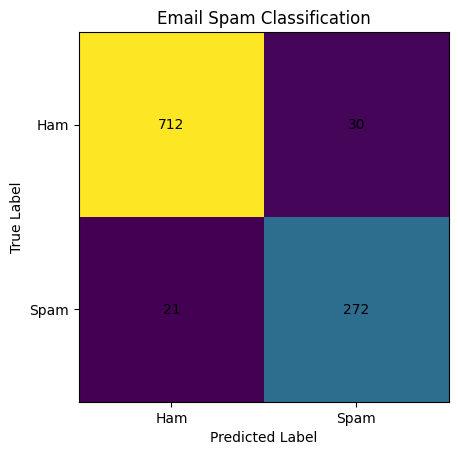

In [32]:
# Evaluate the model
y_pred = model.predict(X_test_tfidf)

print("Accuracy:", round(accuracy_score(y_test, y_pred)*100,2), "%")
print("Classification Report:\n")
print(classification_report(
y_test, y_pred,
target_names=["Ham", "Spam"],
zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

plt.imshow(cm)
plt.title("Email Spam Classification")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks([0, 1], ["Ham", "Spam"])
plt.yticks([0, 1], ["Ham", "Spam"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="black")

plt.show()

In [ ]:
# Test custom emails (OPTIONAL)
emails = [
    "Congratulations! You have won a cash prize. Claim your reward now.",
    "Hi team, please find the meeting notes attached. Thank you.",
    "URGENT: You have been selected for a free gift. Click here to claim."
]

emails_cleaned = [preprocess_text(email) for email in emails]
emails_tfidf = vectorizer.transform(emails_cleaned)

predictions = model.predict(emails_tfidf)

for email, prediction in zip(emails, predictions):
    result = "Spam" if prediction == 1 else "Ham (Not Spam)"
    print("\nEmail:", email)
    print("Prediction:", result)


Email: Congratulations! You have won a cash prize. Claim your reward now.
Prediction: Spam

Email: Hi team, please find the meeting notes attached. Thank you.
Prediction: Ham (Not Spam)

Email: URGENT: You have been selected for a free gift. Click here to claim.
Prediction: Spam
